# BÀI TẬP LỚN MÔN HỌC MÁY (CO3117) - ĐẠI HỌC BÁCH KHOA ĐHQG-HCM
## ĐỀ TÀI: Ứng dụng SVM, Naive Bayes, Logistic Regression và XGBoost vào bài toán phân loại review quần áo phụ nữ
**Giảng viên hướng dẫn:** Th.S Võ Thanh Hùng  
**Bộ dữ liệu:** [Women's E-Commerce Clothing Reviews (Kaggle)](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews)  

---
### TỔNG QUAN NỘI DUNG THỰC NGHIỆM
Notebook này hợp nhất và chuẩn hóa toàn bộ quy trình thực nghiệm của nhóm:
1. **Khám phá và tiền xử lý dữ liệu (EDA & Data Preprocessing):** Phân tích mất cân bằng lớp (82.2% vs 17.8%), phân bố độ dài, ghép văn bản Title + Review Text và chia tập Stratified 80:20.
2. **Khảo sát biểu diễn văn bản & Lọc đặc trưng:** So sánh CountVectorizer vs TfidfVectorizer; Lựa chọn đặc trưng SelectKBest với Chi-Square ($\chi^2$) và ANOVA F-Score.
3. **Khảo sát Kernel của Support Vector Machine (SVM):** So sánh Linear, RBF, Polynomial và Sigmoid.
4. **Mô hình cơ sở (Baseline Models):** Thiết lập chuẩn tham chiếu cho Logistic Regression, Naive Bayes, XGBoost và SVM.
5. **Tinh chỉnh siêu tham số (Hyperparameter Tuning):** Áp dụng `RandomizedSearchCV` kết hợp Stratified 5-Fold Cross-Validation tối ưu `f1_macro` cho cả 4 lớp mô hình.
6. **Kỹ thuật nâng cao mở rộng (Advanced Experiments):**
   - Học kết hợp (Ensemble Learning) cho SVM: BaggingClassifier vs AdaBoostClassifier.
   - Xây dựng Pipeline khép kín cho LinearSVC (Tfidf + SelectKBest + Bagging LinearSVC).
   - Tích hợp siêu dữ liệu (XGBoost with Metadata: kết hợp TF-IDF với Age và OneHotEncoder cho Division, Department, Class Name).
7. **Đánh giá và so sánh toàn diện:** Tổng hợp bảng chỉ số (Accuracy, F1 các lớp, Macro-F1, Recall lớp 0, ROC-AUC, Thời gian huấn luyện), phân tích Overfitting (Train-Test Gap), Confusion Matrix.
8. **Khả năng diễn giải mô hình & Phân tích lỗi (Interpretability & Error Analysis):** Khám phá các từ ngữ chi phối quyết định phân loại và mổ xẻ các mẫu dự đoán sai lệch điển hình.


## 1. Cấu hình môi trường & Tải tập dữ liệu tự động



In [1]:
# Cài đặt các thư viện cần thiết nếu chạy trên Colab mới
# %pip install -q scikit-learn xgboost pandas numpy matplotlib seaborn joblib

import os
import sys
import time
import shutil
import urllib.request
import warnings
import datetime as dt

import pandas as pd
import numpy as np
from scipy.stats import loguniform, randint, uniform
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, precision_score,
    roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# XGBoost
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
%matplotlib inline

# Phát hiện phần cứng (GPU hay CPU)
device_type = 'cpu'
try:
    import torch
    if torch.cuda.is_available():
        device_type = 'cuda'
except Exception:
    if shutil.which('nvidia-smi'):
        device_type = 'cuda'

print(f"-> Môi trường thực thi: Thiết bị tăng tốc = {device_type.upper()}")

# Tự động tải dataset nếu chưa tồn tại
DATASET_FILENAME = "Womens Clothing E-Commerce Reviews.csv"
DATASET_URL = "https://raw.githubusercontent.com/AFAgarap/ecommerce-reviews-analysis/master/Womens%20Clothing%20E-Commerce%20Reviews.csv"

if not os.path.exists(DATASET_FILENAME):
    print(f"-> Đang tải tập dữ liệu '{DATASET_FILENAME}' từ GitHub...")
    try:
        urllib.request.urlretrieve(DATASET_URL, DATASET_FILENAME)
        print("-> Tải dữ liệu thành công!")
    except Exception as e:
        print(f"-> Lỗi khi tải dữ liệu tự động: {e}. Vui lòng tải file thủ công lên thư mục làm việc.")
else:
    print(f"-> Đã tìm thấy file dữ liệu: {DATASET_FILENAME}")



-> Môi trường thực thi: Thiết bị tăng tốc = CUDA
-> Đã tìm thấy file dữ liệu: Womens Clothing E-Commerce Reviews.csv


## 2. Khám phá Dữ liệu (Exploratory Data Analysis - EDA)
Ta đọc file dữ liệu, khảo sát các thuộc tính, tỷ lệ nhãn mục tiêu `Recommended IND` và kiểm tra sự mất cân bằng dữ liệu.


Kích thước tập dữ liệu: 23486 dòng, 10 cột

Thông tin 5 dòng đầu tiên:


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses



Số lượng giá trị khuyết thiếu (Missing Values):
Title              3810
Review Text         845
Division Name        14
Department Name      14
Class Name           14
dtype: int64

Phân bố nhãn mục tiêu (Recommended IND):
  Lớp 1: 19314 mẫu (82.24%)
  Lớp 0: 4172 mẫu (17.76%)


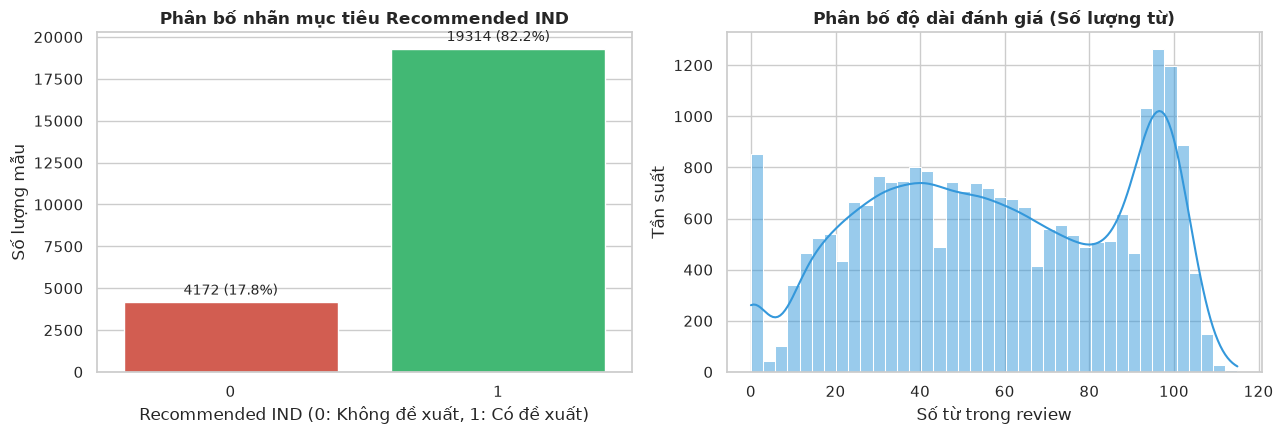


Ma trận tương quan giữa Rating và Recommended IND (Target Leakage):


Recommended IND,0,1
Rating,,
1,0.981,0.019
2,0.940,0.060
3,0.586,0.414
4,0.033,0.967
5,0.002,0.998


In [2]:
df = pd.read_csv(DATASET_FILENAME)
# Loại bỏ cột index thừa nếu có
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

print(f"Kích thước tập dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\nThông tin 5 dòng đầu tiên:")
display(df.head())

print("\nSố lượng giá trị khuyết thiếu (Missing Values):")
missing = df.isna().sum()
print(missing[missing > 0])

# Tỷ lệ nhãn phân loại
class_counts = df['Recommended IND'].value_counts()
class_ratio = df['Recommended IND'].value_counts(normalize=True)
print("\nPhân bố nhãn mục tiêu (Recommended IND):")
for label, count in class_counts.items():
    print(f"  Lớp {label}: {count} mẫu ({class_ratio[label]*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Biểu đồ 1: Phân bố nhãn
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Phân bố nhãn mục tiêu Recommended IND', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Recommended IND (0: Không đề xuất, 1: Có đề xuất)')
axes[0].set_ylabel('Số lượng mẫu')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# Biểu đồ 2: Phân bố độ dài từ của review
review_lengths = df['Review Text'].fillna('').str.split().str.len()
sns.histplot(review_lengths, bins=40, kde=True, ax=axes[1], color='#3498db')
axes[1].set_title('Phân bố độ dài đánh giá (Số lượng từ)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Số từ trong review')
axes[1].set_ylabel('Tần suất')

plt.tight_layout()
plt.show()

# Kiểm tra quan hệ giữa Rating và Recommended IND (Lý do không dùng Rating làm feature để tránh target leakage)
print("\nMa trận tương quan giữa Rating và Recommended IND (Target Leakage):")
display(pd.crosstab(df['Rating'], df['Recommended IND'], normalize='index').round(3))



## 3. Tiền xử lý Dữ liệu & Phân chia Train/Test
- **Ghép nội dung văn bản:** Trường `Title` chứa nhiều từ mang sắc thái tình cảm cô đọng (ví dụ: *"Love it"*, *"Flattering shirt"*, *"Poor quality"*), do đó kết hợp `Title` và `Review Text` thành một trường văn bản hoàn chỉnh `text`.
- **Xử lý giá trị thiếu:** Điền chuỗi rỗng `''` cho text và điền `'Unknown'` cho các thuộc tính phân loại (`Division Name`, `Department Name`, `Class Name`).
- **Phân chia tập dữ liệu:** Sử dụng tỷ lệ 80:20 với phương pháp phân tầng (`stratify=y`) và hạt giống ngẫu nhiên cố định (`random_state=42`) để đảm bảo tính nhất quán trên toàn bộ các mô hình.
- **Tính hệ số mất cân bằng lớp:** `scale_pos_weight = n_neg / n_pos` dùng cho XGBoost.


In [3]:
# Điền giá trị khuyết thiếu
df['Title'] = df['Title'].fillna('')
df['Review Text'] = df['Review Text'].fillna('')
df['text'] = (df['Title'] + ' ' + df['Review Text']).str.strip()

for col in ['Division Name', 'Department Name', 'Class Name']:
    df[col] = df[col].fillna('Unknown')

y = df['Recommended IND'].astype(int)
X = df[['text', 'Age', 'Division Name', 'Department Name', 'Class Name']]

# Phân chia dữ liệu Stratified 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_text = X_train['text']
X_test_text = X_test['text']

# Tính toán hệ số cân bằng cho XGBoost
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
spw = n_neg / n_pos

print(f"Kích thước tập Train: {X_train.shape[0]} mẫu (Lớp 1: {n_pos}, Lớp 0: {n_neg})")
print(f"Kích thước tập Test:  {X_test.shape[0]} mẫu (Lớp 1: {(y_test==1).sum()}, Lớp 0: {(y_test==0).sum()})")
print(f"Tỷ lệ lớp 1 - Train: {y_train.mean():.4f} | Test: {y_test.mean():.4f}")
print(f"Hệ số scale_pos_weight (XGBoost): {spw:.4f}")



Kích thước tập Train: 18788 mẫu (Lớp 1: 15451, Lớp 0: 3337)
Kích thước tập Test:  4698 mẫu (Lớp 1: 3863, Lớp 0: 835)
Tỷ lệ lớp 1 - Train: 0.8224 | Test: 0.8223
Hệ số scale_pos_weight (XGBoost): 0.2160


## 4. Khảo sát Biểu diễn Văn bản & Lựa chọn Đặc trưng
### 4.1 So sánh phương pháp Tokenization (CountVectorizer vs TfidfVectorizer)
Sử dụng mô hình chuẩn `LinearSVC` để đánh giá tính hiệu quả giữa:
- **CountVectorizer (Bag-of-Words):** Đếm tần số xuất hiện của từng từ.
- **TfidfVectorizer:** Chuẩn hóa tần suất từ bằng nghịch đảo tần suất tài liệu (TF-IDF), làm mờ các từ xuất hiện đại trà và làm nổi bật các từ có tính phân loại cao.


In [4]:
tokenizers = {
    "CountVectorizer": CountVectorizer(),
    "TfidfVectorizer": TfidfVectorizer()
}

tok_eval_list = []
for name, vec in tokenizers.items():
    t0 = time.time()
    X_tr_vec = vec.fit_transform(X_train_text)
    X_te_vec = vec.transform(X_test_text)

    clf = LinearSVC(random_state=42, max_iter=2000)
    clf.fit(X_tr_vec, y_train)
    preds = clf.predict(X_te_vec)
    dur = time.time() - t0

    tok_eval_list.append({
        'Phương pháp Tokenize': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'F1-Score (Macro)': round(f1_score(y_test, preds, average='macro'), 4),
        'F1-Score (Class 1)': round(f1_score(y_test, preds, pos_label=1), 4),
        'Thời gian (giây)': round(dur, 2)
    })

df_tok_results = pd.DataFrame(tok_eval_list)
print("Kết quả so sánh Tokenization:")
display(df_tok_results)



Kết quả so sánh Tokenization:


,Phương pháp Tokenize,Accuracy,F1-Score (Macro),F1-Score (Class 1),Thời gian (giây)
0,CountVectorizer,0.8846,0.7959,0.9305,4.95
1,TfidfVectorizer,0.9025,0.8218,0.9417,1.72


### 4.2 Lựa chọn Đặc trưng (Feature Selection) với Filter Methods
Không gian từ vựng n-gram sau TF-IDF thường có số chiều rất lớn chứa nhiều từ thưa và nhiễu. Ta khảo sát phương pháp lọc `SelectKBest` với hai kiểm định thống kê:
- **Chi-Square ($\chi^2$):** Kiểm tra tính độc lập giữa sự xuất hiện của từ và phân bố nhãn.
- **ANOVA F-Score:** So sánh phương sai giữa các nhóm nhãn với phương sai nội bộ từng nhóm.

Khảo sát qua các giá trị $k \in \{500, 1000, 2000, 3000\}$.


F1-Score (Macro) của các phương pháp lựa chọn đặc trưng:


Phương pháp,ANOVA F-Score,Chi-Square
Số lượng đặc trưng k,,
500,0.8325,0.8304
1000,0.8337,0.8303
2000,0.8374,0.8342
3000,0.8351,0.8329


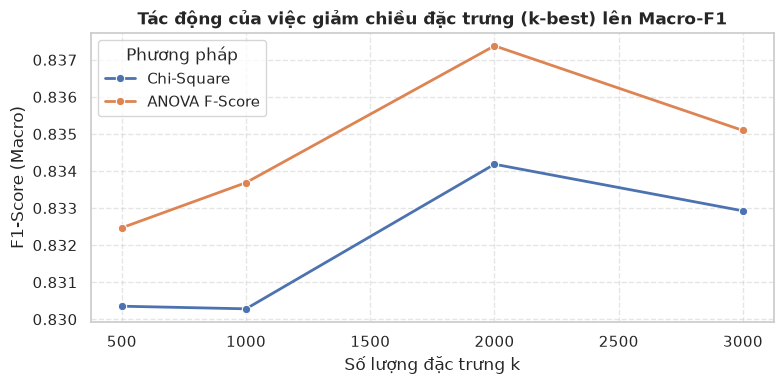

In [5]:
shared_tfidf = TfidfVectorizer()
X_train_shared = shared_tfidf.fit_transform(X_train_text)
X_test_shared = shared_tfidf.transform(X_test_text)

fs_algorithms = {
    'Chi-Square': chi2,
    'ANOVA F-Score': f_classif
}
k_values = [500, 1000, 2000, 3000]

fs_results = []
for fs_name, score_func in fs_algorithms.items():
    for k in k_values:
        selector = SelectKBest(score_func=score_func, k=k)
        X_tr_fs = selector.fit_transform(X_train_shared, y_train)
        X_te_fs = selector.transform(X_test_shared)

        clf = LinearSVC(random_state=42, max_iter=2000)
        clf.fit(X_tr_fs, y_train)
        preds = clf.predict(X_te_fs)

        fs_results.append({
            'Phương pháp': fs_name,
            'Số lượng đặc trưng k': k,
            'F1-Score (Macro)': f1_score(y_test, preds, average='macro'),
            'Accuracy': accuracy_score(y_test, preds)
        })

df_fs = pd.DataFrame(fs_results)
print("F1-Score (Macro) của các phương pháp lựa chọn đặc trưng:")
display(df_fs.pivot(index='Số lượng đặc trưng k', columns='Phương pháp', values='F1-Score (Macro)').round(4))

# Trực quan hóa tác động của việc giảm số chiều k
plt.figure(figsize=(8, 4))
sns.lineplot(data=df_fs, x='Số lượng đặc trưng k', y='F1-Score (Macro)', hue='Phương pháp', marker='o', linewidth=2)
plt.title("Tác động của việc giảm chiều đặc trưng (k-best) lên Macro-F1", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



## 5. Khảo sát các Hàm Kernel cho Support Vector Machine (SVM)
Ta so sánh 4 hàm Kernel phổ biến trên cùng tập dữ liệu biểu diễn bằng TF-IDF (sử dụng tập mẫu phân tầng 4000 quan sát để đánh giá nhanh thời gian huấn luyện và độ hội tụ):
1. **Linear Kernel:** $K(x, x') = x^\top x'$
2. **RBF Kernel:** $K(x, x') = \exp(-\gamma \|x - x'\|^2)$
3. **Polynomial Kernel:** $K(x, x') = (\gamma x^\top x' + r)^d$ ($d=2$)
4. **Sigmoid Kernel:** $K(x, x') = \tanh(\gamma x^\top x' + r)$


In [6]:
# Lấy mẫu nhỏ 4000 quan sát để kiểm thử nhanh các kernel
X_sub_tr, _, y_sub_tr, _ = train_test_split(
    X_train_shared, y_train, train_size=4000, random_state=42, stratify=y_train
)

kernel_candidates = {
    'SVC (Linear)': SVC(kernel='linear', random_state=42),
    'SVC (RBF)': SVC(kernel='rbf', gamma='scale', random_state=42),
    'SVC (Poly, deg=2)': SVC(kernel='poly', degree=2, random_state=42),
    'SVC (Sigmoid)': SVC(kernel='sigmoid', random_state=42)
}

kernel_results = []
for k_name, model in kernel_candidates.items():
    t0 = time.time()
    model.fit(X_sub_tr, y_sub_tr)
    preds = model.predict(X_test_shared)
    dur = time.time() - t0

    kernel_results.append({
        'SVM Kernel': k_name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'F1 (Class 1)': round(f1_score(y_test, preds, pos_label=1), 4),
        'Macro-F1': round(f1_score(y_test, preds, average='macro'), 4),
        'Thời gian huấn luyện (giây)': round(dur, 2)
    })

df_kernels = pd.DataFrame(kernel_results)
print("So sánh hiệu năng các hàm Kernel của SVM:")
display(df_kernels)



So sánh hiệu năng các hàm Kernel của SVM:


,SVM Kernel,Accuracy,F1 (Class 1),Macro-F1,Thời gian huấn luyện (giây)
0,SVC (Linear),0.8946,0.9380,0.7936,7.19
1,SVC (RBF),0.8817,0.9318,0.7431,11.01
2,"SVC (Poly, deg=2)",0.8650,0.9232,0.6845,11.79
3,SVC (Sigmoid),0.8929,0.9371,0.7885,6.59


## 6. Huấn luyện Mô hình Cơ sở (Baseline Models)
Ta thiết lập khung đánh giá chuẩn (`results` dictionary và `fitted` dict) để đối chiếu mọi mô hình trên cùng tập test 20% độc lập:
- Các chỉ số được theo dõi: `Accuracy`, `F1 (Class 1)`, `F1 (Class 0)`, `Macro F1`, `Recall (Class 0)`, `ROC_AUC`, `Fit Time (s)`.
- Các mô hình baseline:
  - **Logistic Regression (baseline):** $C=1.0$, `class_weight='balanced'`.
  - **Multinomial Naive Bayes (baseline):** $\alpha=0.1$.
  - **XGBoost (baseline):** $N=300$, depth=6, `scale_pos_weight=spw`, histogram GPU/CPU.
  - **SVM (LinearSVC baseline):** $C=1.0$, `class_weight='balanced'`.


In [7]:
results = {}
fitted = {}

def add_res(name, model, X_eval, y_eval, fit_time):
    y_pred = model.predict(X_eval)

    # Một số mô hình không có predict_proba (hoặc LinearSVC), dùng decision_function
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_eval)[:, 1]
    elif hasattr(model, "decision_function"):
        df_vals = model.decision_function(X_eval)
        probs = (df_vals - df_vals.min()) / (df_vals.max() - df_vals.min() + 1e-8)
    else:
        probs = y_pred

    results[name] = {
        'Model': name,
        'Accuracy': accuracy_score(y_eval, y_pred),
        'F1 (Class 1)': f1_score(y_eval, y_pred, pos_label=1),
        'F1 (Class 0)': f1_score(y_eval, y_pred, pos_label=0),
        'Macro F1': f1_score(y_eval, y_pred, average='macro'),
        'Recall (Class 0)': recall_score(y_eval, y_pred, pos_label=0),
        'ROC_AUC': roc_auc_score(y_eval, probs),
        'Fit Time (s)': round(fit_time, 2)
    }
    fitted[name] = (model, X_eval)

def show_results():
    out = pd.DataFrame(results.values()).sort_values('Macro F1', ascending=False).reset_index(drop=True)
    return out.round(4)

# Định nghĩa Pipeline TF-IDF cơ sở
def tfidf_base():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

# Khởi tạo các baseline
baselines = {
    'LogReg (baseline)': Pipeline([
        ('tfidf', tfidf_base()),
        ('clf', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=42)),
    ]),
    'NaiveBayes (baseline)': Pipeline([
        ('tfidf', tfidf_base()),
        ('clf', MultinomialNB(alpha=0.1)),
    ]),
    'XGBoost (baseline)': Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=5000)),
        ('clf', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                              colsample_bytree=0.8, scale_pos_weight=spw, tree_method='hist',
                              eval_metric='logloss', n_jobs=1, random_state=42, device=device_type)),
    ]),
    'SVM-Linear (baseline)': Pipeline([
        ('tfidf', tfidf_base()),
        ('clf', LinearSVC(C=1.0, class_weight='balanced', random_state=42, max_iter=2000)),
    ])
}

for name, pipe in baselines.items():
    t0 = time.time()
    pipe.fit(X_train_text, y_train)
    add_res(name, pipe, X_test_text, y_test, time.time() - t0)

print("Kết quả các mô hình cơ sở (Baseline Models):")
show_results()



Kết quả các mô hình cơ sở (Baseline Models):


,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,SVM-Linear (baseline),0.9132,0.9470,0.7594,0.8532,0.7713,0.9482,3.01
1,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.53
2,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,8.66
3,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.98


## 7. Tinh chỉnh Siêu tham số (Hyperparameter Tuning với RandomizedSearchCV)
Sử dụng `RandomizedSearchCV` kết hợp Stratified 5-Fold Cross-Validation và hàm mục tiêu `scoring='f1_macro'`:
1. **Logistic Regression:** Khảo sát $C \sim \text{loguniform}(10^{-2}, 10^2)$, `ngram_range`, `min_df`, `max_features`, `sublinear_tf`.
2. **Multinomial Naive Bayes:** Khảo sát $\alpha \sim \text{loguniform}(10^{-3}, 2)$, `fit_prior`, `ngram_range`, `min_df`, `max_features`.
3. **XGBoost:** Khảo sát `learning_rate`, `max_depth`, `n_estimators`, `subsample`, `colsample_bytree`, `min_child_weight`.
4. **LinearSVC Pipeline:** Khảo sát $C \sim \text{loguniform}(0.1, 5.0)$, `ngram_range`, `max_features`, `sublinear_tf` và số đặc trưng $k \in \{2000, 3000, \text{all}\}$ với `SelectKBest`.


In [8]:
def run_search(name, pipe, param_dist, n_iter, cv_splits=5, n_jobs=-1):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring='f1_macro',
        n_jobs=n_jobs,
        cv=cv,
        verbose=1,
        random_state=42,
        refit=True
    )

    t0 = time.time()
    search.fit(X_train_text, y_train)
    elapsed = time.time() - t0

    print(f'\n[{name}] Tổng thời gian tìm kiếm: {elapsed:.1f}s')
    print('=' * 60)
    print(f'CẤU HÌNH TỐI ƯU: {name}')
    print(f'Best CV Macro-F1: {search.best_score_:.4f}')
    print('Các tham số tốt nhất:')
    for p, v in search.best_params_.items():
        print(f'  {p}: {v}')
    print('=' * 60)

    add_res(name, search.best_estimator_, X_test_text, y_test, search.refit_time_)
    return search



In [9]:
# 7.1 Tuning Logistic Regression
lr_pipe = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000, random_state=42))
])

lr_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_features': [None, 20000, 50000],
    'tfidf__sublinear_tf': [True, False],
    'clf__C': loguniform(1e-2, 1e2)
}

lr_search = run_search('LogReg (tuned)', lr_pipe, lr_params, n_iter=15, cv_splits=5, n_jobs=-1)



Fitting 5 folds for each of 15 candidates, totalling 75 fits

[LogReg (tuned)] Tổng thời gian tìm kiếm: 38.6s
CẤU HÌNH TỐI ƯU: LogReg (tuned)
Best CV Macro-F1: 0.8559
Các tham số tốt nhất:
  clf__C: 10.506199451597043
  tfidf__max_features: 20000
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 2)
  tfidf__sublinear_tf: False


In [10]:
# 7.2 Tuning Multinomial Naive Bayes
nb_pipe = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', MultinomialNB())
])

nb_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'tfidf__min_df': [1, 2, 3, 5],
    'tfidf__max_features': [None, 20000, 50000],
    'tfidf__sublinear_tf': [True, False],
    'clf__alpha': loguniform(1e-3, 2),
    'clf__fit_prior': [True, False]
}

nb_search = run_search('NaiveBayes (tuned)', nb_pipe, nb_params, n_iter=15, cv_splits=5, n_jobs=-1)



Fitting 5 folds for each of 15 candidates, totalling 75 fits

[NaiveBayes (tuned)] Tổng thời gian tìm kiếm: 35.7s
CẤU HÌNH TỐI ƯU: NaiveBayes (tuned)
Best CV Macro-F1: 0.8285
Các tham số tốt nhất:
  clf__alpha: 0.053987957145223434
  clf__fit_prior: True
  tfidf__max_features: 20000
  tfidf__min_df: 5
  tfidf__ngram_range: (1, 3)
  tfidf__sublinear_tf: False


In [11]:
# 7.3 Tuning XGBoost
xgb_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, dtype=np.float32)),
    ('clf', XGBClassifier(scale_pos_weight=spw, tree_method='hist', device=device_type, eval_metric='logloss', n_jobs=1, random_state=42)),
])

xgb_params = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__min_df': [2, 3],
    'tfidf__max_features': [3000, 5000, 10000],
    'clf__max_depth': randint(3, 8),
    'clf__n_estimators': randint(200, 600),
    'clf__learning_rate': loguniform(0.03, 0.3),
    'clf__subsample': uniform(0.6, 0.4),
    'clf__colsample_bytree': uniform(0.4, 0.6),
    'clf__min_child_weight': randint(1, 8)
}

# n_jobs=1 để tối ưu bộ nhớ GPU/CPU khi train XGBoost
xgb_search = run_search('XGBoost (tuned)', xgb_pipe, xgb_params, n_iter=10, cv_splits=3, n_jobs=1)



Fitting 3 folds for each of 10 candidates, totalling 30 fits

[XGBoost (tuned)] Tổng thời gian tìm kiếm: 150.1s
CẤU HÌNH TỐI ƯU: XGBoost (tuned)
Best CV Macro-F1: 0.8242
Các tham số tốt nhất:
  clf__colsample_bytree: 0.6294771947602976
  clf__learning_rate: 0.2886370920872816
  clf__max_depth: 3
  clf__min_child_weight: 3
  clf__n_estimators: 506
  clf__subsample: 0.8721230154351118
  tfidf__max_features: 3000
  tfidf__min_df: 2
  tfidf__ngram_range: (1, 2)


In [12]:
# 7.4 Tuning LinearSVC Pipeline (tối ưu f1_macro bằng RandomizedSearchCV)
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

svm_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(min_df=2)),
    ('selector', SelectKBest(score_func=chi2)),
    ('clf', LinearSVC(class_weight='balanced', random_state=42, max_iter=5000))
])

svm_params = {
    'tfidf__ngram_range': [(1, 2), (1, 3)],
    'tfidf__max_features': [5000, 20000, None],
    'tfidf__sublinear_tf': [True, False],
    'selector__k': [2000, 3000, 'all'],
    'clf__C': loguniform(0.1, 5.0),
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
svm_search = RandomizedSearchCV(
    estimator=svm_pipe,
    param_distributions=svm_params,
    n_iter=20,
    cv=cv_strat,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    random_state=42,
    refit=True,
    return_train_score=True
)

t0 = time.time()
svm_search.fit(X_train_text, y_train)
print(f"LinearSVC RandomizedSearchCV hoàn tất trong {time.time() - t0:.1f}s")
print(f"SVM Best Parameters: {svm_search.best_params_}")
print(f"SVM Best CV Macro-F1: {svm_search.best_score_:.4f}")

add_res('SVM (tuned)', svm_search.best_estimator_, X_test_text, y_test, svm_search.refit_time_)
show_results()

Fitting 5 folds for each of 20 candidates, totalling 100 fits
LinearSVC RandomizedSearchCV hoàn tất trong 86.2s
SVM Best Parameters: {'clf__C': np.float64(1.0873416514163665), 'selector__k': 'all', 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 3), 'tfidf__sublinear_tf': True}
SVM Best CV Macro-F1: 0.8538


,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,SVM (tuned),0.9195,0.9510,0.7761,0.8635,0.7844,0.9508,6.08
1,SVM-Linear (baseline),0.9132,0.9470,0.7594,0.8532,0.7713,0.9482,3.01
2,LogReg (tuned),0.9106,0.9450,0.7605,0.8528,0.7988,0.9478,3.56
3,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.53
4,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,8.66
5,XGBoost (tuned),0.8993,0.9377,0.7374,0.8375,0.7952,0.9381,5.98
6,NaiveBayes (tuned),0.9017,0.9407,0.7116,0.8262,0.6826,0.9445,7.67
7,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.98


## 8. Kỹ thuật Mở rộng Nâng cao (Advanced Experiments)
### 8.1 Ensemble Learning cho Support Vector Machine
Khảo sát hai kỹ thuật học kết hợp trên không gian đặc trưng TF-IDF:
1. **Bagging (Bootstrap Aggregating):** Giảm phương sai bằng cách huấn luyện song song $M=10$ mô hình cơ sở `LinearSVC` trên các tập con mẫu lấy ngẫu nhiên có hoàn lại (`max_samples=0.8`).
2. **Boosting (AdaBoost):** Giảm độ chệch bằng cách huấn luyện tuần tự các bộ phân loại yếu, tập trung tăng trọng số cho các mẫu bị phân loại sai ở bước trước.
3. **Xây dựng Pipeline khép kín cho LinearSVC:** Tích hợp `TfidfVectorizer` -> `SelectKBest` -> `BaggingClassifier(LinearSVC)`.


In [13]:
# Trích xuất các tham số tối ưu đã tìm được cho LinearSVC
svm_best_p = svm_search.best_params_
tf_svm_params = {k.replace('tfidf__', ''): v for k, v in svm_best_p.items() if k.startswith('tfidf__')}
sel_svm_params = {k.replace('selector__', ''): v for k, v in svm_best_p.items() if k.startswith('selector__')}
svm_clf_params = {k.replace('clf__', ''): v for k, v in svm_best_p.items() if k.startswith('clf__')}

# Xây dựng Pipeline hoàn chỉnh khép kín: Tfidf -> SelectKBest -> Bagging(LinearSVC)
svm_pipeline_complete = Pipeline([
    ('tfidf', TfidfVectorizer(min_df=2, **tf_svm_params)),
    ('selector', SelectKBest(score_func=chi2, **sel_svm_params)),
    ('bagging_svm', BaggingClassifier(
        estimator=LinearSVC(class_weight='balanced', random_state=42, max_iter=5000, **svm_clf_params),
        n_estimators=10,
        max_samples=0.8,
        random_state=42,
        n_jobs=1
    ))
])

t0 = time.time()
svm_pipeline_complete.fit(X_train_text, y_train)
dur = time.time() - t0
print(f"Huấn luyện LinearSVC Complete Pipeline hoàn tất trong {dur:.2f}s")
add_res('LinearSVC + Bagging Pipeline', svm_pipeline_complete, X_test_text, y_test, dur)

# Thử nghiệm so sánh nhanh Bagging vs AdaBoost
ensemble_models = {
    'Bagging (LinearSVC)': BaggingClassifier(
        estimator=LinearSVC(C=0.5, random_state=42),
        n_estimators=10, max_samples=0.8, random_state=42, n_jobs=1
    ),
    'AdaBoostClassifier': AdaBoostClassifier(n_estimators=50, random_state=42)
}

ens_records = []
for ens_name, model in ensemble_models.items():
    t0 = time.time()
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000)),
        ('ens', model)
    ])
    pipe.fit(X_train_text, y_train)
    dur = time.time() - t0
    preds = pipe.predict(X_test_text)
    ens_records.append({
        'Mô hình Ensemble': ens_name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'F1-Score (Macro)': round(f1_score(y_test, preds, average='macro'), 4),
        'F1-Score (Class 1)': round(f1_score(y_test, preds, pos_label=1), 4),
        'Thời gian (s)': round(dur, 2)
    })

df_ens = pd.DataFrame(ens_records)
print("\nSo sánh các phương pháp Ensemble:")
display(df_ens)



Huấn luyện LinearSVC Complete Pipeline hoàn tất trong 18.03s

So sánh các phương pháp Ensemble:


,Mô hình Ensemble,Accuracy,F1-Score (Macro),F1-Score (Class 1),Thời gian (s)
0,Bagging (LinearSVC),0.9044,0.8233,0.9430,2.23
1,AdaBoostClassifier,0.8442,0.6134,0.9121,9.95


### 8.2 Tích hợp Siêu dữ liệu (XGBoost with Metadata)
Bên cạnh nội dung văn bản thuần túy, bộ dữ liệu cung cấp thông tin ngữ cảnh khách hàng và danh mục hàng:
- Cột số học: `Age` (truyền trực tiếp qua `passthrough`).
- Cột phân loại: `Division Name`, `Department Name`, `Class Name` (mã hóa One-Hot bằng `OneHotEncoder(handle_unknown='ignore')`).
- Cột văn bản `text`: Mã hóa TF-IDF với cấu hình tối ưu từ bước tuning XGBoost.
Tất cả được ghép nối liền mạch qua `ColumnTransformer`.


In [14]:
# Trích xuất tham số tối ưu từ tuning XGBoost
xgb_best_params = {k.replace('clf__', ''): v for k, v in xgb_search.best_params_.items() if k.startswith('clf__')}
tf_xgb_params = {k.replace('tfidf__', ''): v for k, v in xgb_search.best_params_.items() if k.startswith('tfidf__')}

meta_preprocessor = ColumnTransformer([
    ('tfidf', TfidfVectorizer(sublinear_tf=True, **tf_xgb_params), 'text'),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['Division Name', 'Department Name', 'Class Name']),
    ('age', 'passthrough', ['Age']),
])

xgb_metadata_pipeline = Pipeline([
    ('pre', meta_preprocessor),
    ('clf', XGBClassifier(**xgb_best_params, scale_pos_weight=spw, tree_method='hist',
                          device=device_type, eval_metric='logloss', n_jobs=1, random_state=42)),
])

t0 = time.time()
xgb_metadata_pipeline.fit(X_train, y_train)
dur = time.time() - t0

add_res('XGBoost + metadata', xgb_metadata_pipeline, X_test, y_test, dur)
print(f"Huấn luyện XGBoost + Metadata hoàn tất trong {dur:.2f}s")
show_results()



Huấn luyện XGBoost + Metadata hoàn tất trong 6.12s


,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,SVM (tuned),0.9195,0.9510,0.7761,0.8635,0.7844,0.9508,6.08
1,LinearSVC + Bagging Pipeline,0.9159,0.9490,0.7605,0.8547,0.7509,0.9020,18.03
2,SVM-Linear (baseline),0.9132,0.9470,0.7594,0.8532,0.7713,0.9482,3.01
3,LogReg (tuned),0.9106,0.9450,0.7605,0.8528,0.7988,0.9478,3.56
4,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.53
5,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,8.66
6,XGBoost (tuned),0.8993,0.9377,0.7374,0.8375,0.7952,0.9381,5.98
7,XGBoost + metadata,0.8972,0.9364,0.7327,0.8345,0.7928,0.9400,6.12
8,NaiveBayes (tuned),0.9017,0.9407,0.7116,0.8262,0.6826,0.9445,7.67
9,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.98


## 9. Tổng hợp Kết quả Thực nghiệm & So sánh Toàn diện
Phần này tổng kết và đối chiếu toàn bộ các mô hình học máy:
1. **Bảng chỉ số tổng thể:** Accuracy, F1 (Lớp 1), F1 (Lớp 0), Macro-F1, Recall (Lớp 0), ROC-AUC, Fit Time.
2. **Biểu đồ so sánh:** Trực quan hóa các thước đo chất lượng.
3. **Phân tích hiện tượng quá khớp (Overfitting Analysis):** Đánh giá chênh lệch điểm số (Train-Test Gap) trên thước đo Macro-F1.
4. **Ma trận nhầm lẫn (Confusion Matrices):** Đánh giá phân bố dự đoán của các mô hình xuất sắc nhất.


BẢNG TỔNG HỢP HIỆU NĂNG TẤT CẢ CÁC MÔ HÌNH TRÊN TẬP TEST


,Model,Accuracy,F1 (Class 1),F1 (Class 0),Macro F1,Recall (Class 0),ROC_AUC,Fit Time (s)
0,SVM (tuned),0.9195,0.9510,0.7761,0.8635,0.7844,0.9508,6.08
1,LinearSVC + Bagging Pipeline,0.9159,0.9490,0.7605,0.8547,0.7509,0.9020,18.03
2,SVM-Linear (baseline),0.9132,0.9470,0.7594,0.8532,0.7713,0.9482,3.01
3,LogReg (tuned),0.9106,0.9450,0.7605,0.8528,0.7988,0.9478,3.56
4,LogReg (baseline),0.9044,0.9402,0.7618,0.8510,0.8599,0.9501,3.53
5,XGBoost (baseline),0.8995,0.9376,0.7415,0.8396,0.8108,0.9419,8.66
6,XGBoost (tuned),0.8993,0.9377,0.7374,0.8375,0.7952,0.9381,5.98
7,XGBoost + metadata,0.8972,0.9364,0.7327,0.8345,0.7928,0.9400,6.12
8,NaiveBayes (tuned),0.9017,0.9407,0.7116,0.8262,0.6826,0.9445,7.67
9,NaiveBayes (baseline),0.9040,0.9433,0.6879,0.8156,0.5952,0.9484,1.98


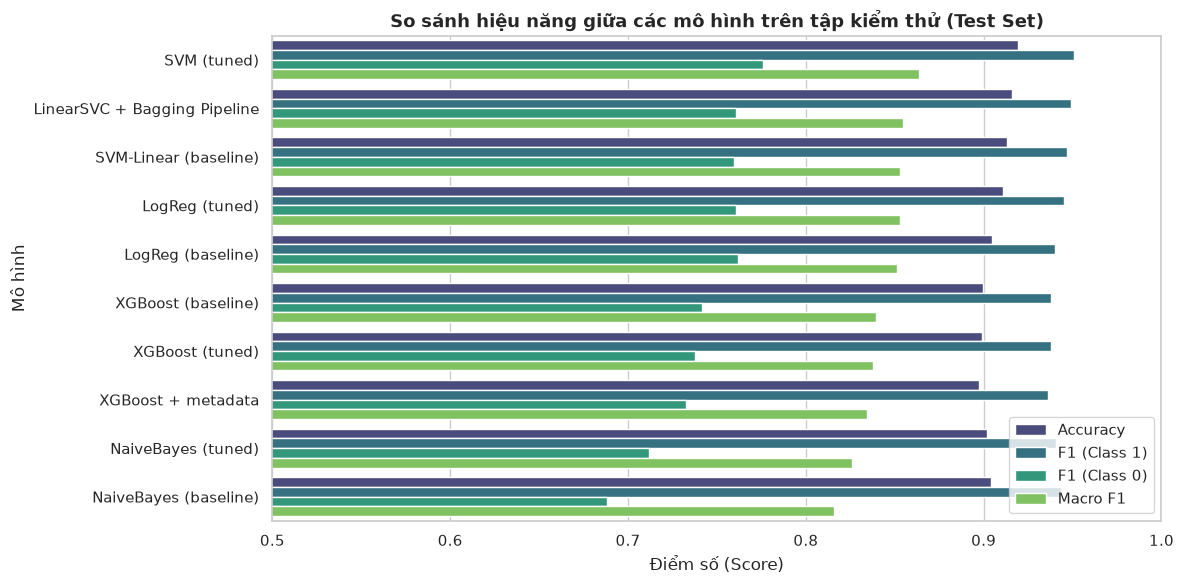

In [15]:
# Bảng kết quả tổng thể sắp xếp theo Macro-F1
final_results_df = show_results()
print("=" * 70)
print("BẢNG TỔNG HỢP HIỆU NĂNG TẤT CẢ CÁC MÔ HÌNH TRÊN TẬP TEST")
print("=" * 70)
display(final_results_df)

# Biểu đồ so sánh trực quan
metrics = ['Accuracy', 'F1 (Class 1)', 'F1 (Class 0)', 'Macro F1']
plot_df = final_results_df.melt(id_vars='Model', value_vars=metrics, var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, y='Model', x='Score', hue='Metric', palette='viridis')
plt.xlim(0.5, 1.0)
plt.title('So sánh hiệu năng giữa các mô hình trên tập kiểm thử (Test Set)', fontsize=13, fontweight='bold')
plt.xlabel('Điểm số (Score)')
plt.ylabel('Mô hình')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()



In [16]:
# 9.2 Phân tích Overfitting: So sánh Macro-F1 giữa tập Train và tập Test
gap_rows = []
for name, (model, X_eval) in fitted.items():
    X_tr = X_train if name.endswith('metadata') else X_train_text
    train_macro = f1_score(y_train, model.predict(X_tr), average='macro')
    test_macro = f1_score(y_test, model.predict(X_eval), average='macro')
    gap_rows.append({
        'Model': name,
        'Macro-F1 (Train)': train_macro,
        'Macro-F1 (Test)': test_macro,
        'Gap (Train - Test)': train_macro - test_macro
    })

gap_df = pd.DataFrame(gap_rows).sort_values('Gap (Train - Test)', ascending=False).reset_index(drop=True)
print("Phân tích khoảng cách hiệu năng Train - Test (Overfitting Gap):")
display(gap_df.round(4))



Phân tích khoảng cách hiệu năng Train - Test (Overfitting Gap):


,Model,Macro-F1 (Train),Macro-F1 (Test),Gap (Train - Test)
0,NaiveBayes (baseline),0.9557,0.8156,0.1401
1,SVM-Linear (baseline),0.9859,0.8532,0.1327
2,SVM (tuned),0.9923,0.8635,0.1288
3,LinearSVC + Bagging Pipeline,0.9607,0.8547,0.1060
4,LogReg (tuned),0.9562,0.8528,0.1034
5,XGBoost + metadata,0.9287,0.8345,0.0942
6,XGBoost (tuned),0.9285,0.8375,0.0909
7,XGBoost (baseline),0.9251,0.8396,0.0855
8,NaiveBayes (tuned),0.8904,0.8262,0.0642
9,LogReg (baseline),0.9068,0.8510,0.0558


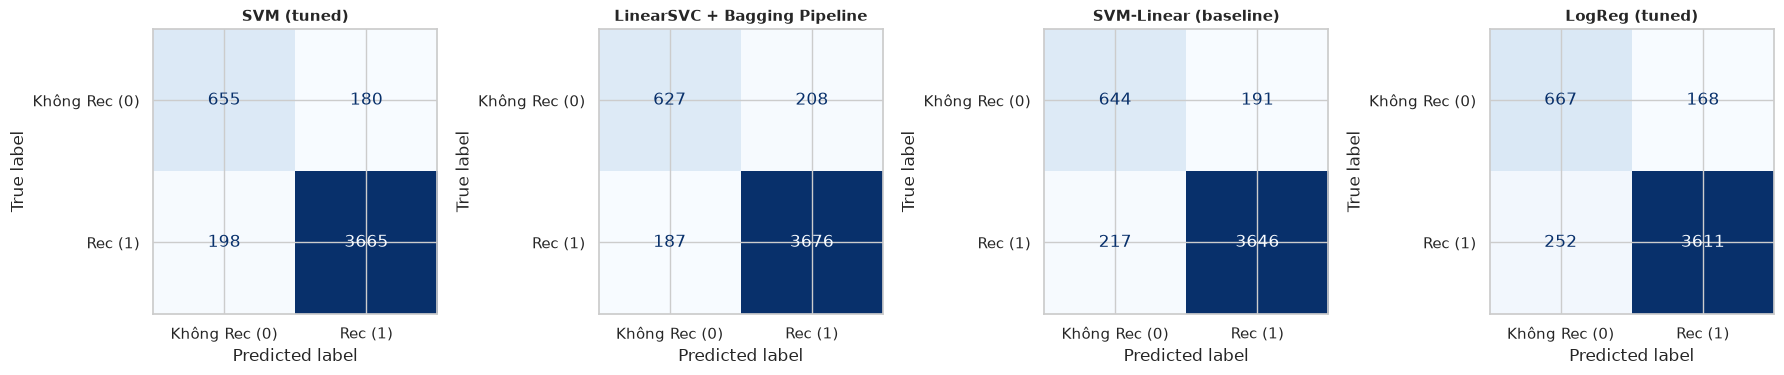


BÁO CÁO CHI TIẾT CỦA MÔ HÌNH XUẤT SẮC NHẤT (SVM (tuned)):
               precision    recall  f1-score   support

Không Rec (0)       0.77      0.78      0.78       835
      Rec (1)       0.95      0.95      0.95      3863

     accuracy                           0.92      4698
    macro avg       0.86      0.87      0.86      4698
 weighted avg       0.92      0.92      0.92      4698



In [17]:
# 9.3 Ma trận nhầm lẫn (Confusion Matrices) của 4 mô hình hàng đầu
top_models = final_results_df['Model'].head(4).tolist()
fig, axes = plt.subplots(1, len(top_models), figsize=(4.5 * len(top_models), 4))
axes = np.atleast_1d(axes)

for ax, name in zip(axes, top_models):
    model, X_eval = fitted[name]
    y_p = model.predict(X_eval)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_p,
        display_labels=['Không Rec (0)', 'Rec (1)'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )
    ax.set_title(name, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Chi tiết Classification Report của mô hình đạt Macro-F1 cao nhất
best_model_name = final_results_df.loc[0, 'Model']
best_model, best_X_eval = fitted[best_model_name]
print(f"\nBÁO CÁO CHI TIẾT CỦA MÔ HÌNH XUẤT SẮC NHẤT ({best_model_name}):")
print(classification_report(y_test, best_model.predict(best_X_eval), target_names=['Không Rec (0)', 'Rec (1)']))



## 10. Khả năng Diễn giải Mô hình & Phân tích Lỗi (Interpretability & Error Analysis)
### 10.1 Các từ ngữ chi phối quyết định (Most Influential Words)
Trích xuất trọng số hồi quy (Coefficients) từ mô hình Logistic Regression tối ưu:
- Hệ số mang giá trị dương lớn: Thúc đẩy mô hình dự đoán nhãn 1 (Recommend).
- Hệ số mang giá trị âm lớn: Thúc đẩy mô hình dự đoán nhãn 0 (Not Recommend).


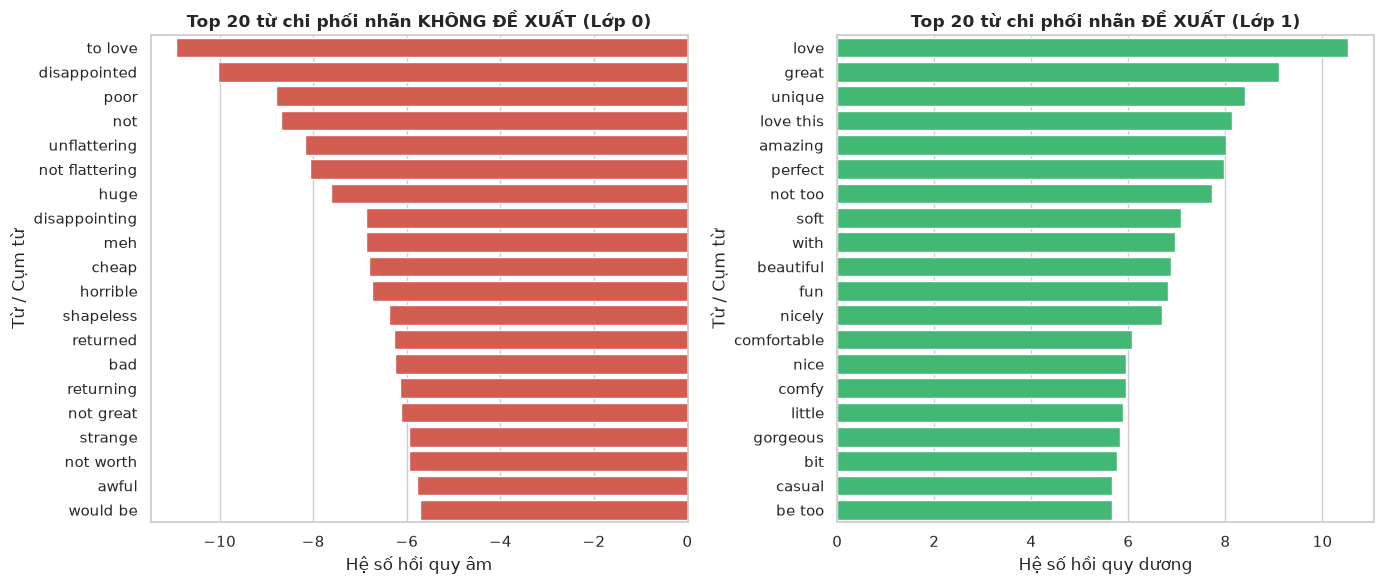

In [18]:
best_lr = lr_search.best_estimator_
vec = best_lr.named_steps['tfidf']
clf = best_lr.named_steps['clf']

feature_names = np.array(vec.get_feature_names_out())
coefficients = clf.coef_[0]
sorted_idx = np.argsort(coefficients)

top_neg = pd.DataFrame({'Từ / Cụm từ': feature_names[sorted_idx[:20]], 'Hệ số (Weight)': coefficients[sorted_idx[:20]]})
top_pos = pd.DataFrame({'Từ / Cụm từ': feature_names[sorted_idx[-20:][::-1]], 'Hệ số (Weight)': coefficients[sorted_idx[-20:][::-1]]})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=top_neg, y='Từ / Cụm từ', x='Hệ số (Weight)', color='#e74c3c', ax=axes[0])
axes[0].set_title('Top 20 từ chi phối nhãn KHÔNG ĐỀ XUẤT (Lớp 0)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hệ số hồi quy âm')

sns.barplot(data=top_pos, y='Từ / Cụm từ', x='Hệ số (Weight)', color='#2ecc71', ax=axes[1])
axes[1].set_title('Top 20 từ chi phối nhãn ĐỀ XUẤT (Lớp 1)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hệ số hồi quy dương')

plt.tight_layout()
plt.show()



### 10.2 Phân tích Lỗi Thực tế (Error Analysis)
Khảo sát các trường hợp mô hình tự tin dự đoán nhưng thực tế lại sai:
1. **False Positives (Thực tế là 0 nhưng mô hình gán 1 với xác suất cao):** Nhận diện các hiện tượng review có chứa từ khen nhẹ nhàng nhưng tổng thể thất vọng, hoặc cấu trúc câu mang tính châm biếm/mỉa mai.
2. **False Negatives (Thực tế là 1 nhưng mô hình gán 0 với xác suất cao):** Nhận diện các review khách hàng đề cập đến nhược điểm (rộng, chật, giao trễ) nhưng vẫn bấm đề xuất sản phẩm.


In [19]:
# Sử dụng Logistic Regression tối ưu để khảo sát xác suất dự đoán
best_eval_model, best_eval_X = fitted['LogReg (tuned)']
pred_probs = best_eval_model.predict_proba(best_eval_X)[:, 1]
preds = best_eval_model.predict(best_eval_X)

err_df = pd.DataFrame({
    'Review Text': X_test['text'].values,
    'Nhãn thực tế': y_test.values,
    'Dự đoán': preds,
    'Xác suất P(Rec=1)': pred_probs.round(4)
})

print("=" * 80)
print("TOP 5 TRƯỜNG HỢP: Thực tế KHÔNG RECOMMEND (0) nhưng mô hình đoán RECOMMEND (1) với độ tự tin cao")
print("=" * 80)
fp_examples = err_df[(err_df['Nhãn thực tế'] == 0) & (err_df['Dự đoán'] == 1)].sort_values('Xác suất P(Rec=1)', ascending=False).head(5)
for i, row in fp_examples.iterrows():
    print(f"- P(Rec=1) = {row['Xác suất P(Rec=1)']:.4f}")
    print(f"  Nội dung: \"{row['Review Text'][:250]}...\"\n")

print("=" * 80)
print("TOP 5 TRƯỜNG HỢP: Thực tế RECOMMEND (1) nhưng mô hình đoán KHÔNG RECOMMEND (0) với độ tự tin cao")
print("=" * 80)
fn_examples = err_df[(err_df['Nhãn thực tế'] == 1) & (err_df['Dự đoán'] == 0)].sort_values('Xác suất P(Rec=1)', ascending=True).head(5)
for i, row in fn_examples.iterrows():
    print(f"- P(Rec=1) = {row['Xác suất P(Rec=1)']:.4f}")
    print(f"  Nội dung: \"{row['Review Text'][:250]}...\"\n")



TOP 5 TRƯỜNG HỢP: Thực tế KHÔNG RECOMMEND (0) nhưng mô hình đoán RECOMMEND (1) với độ tự tin cao
- P(Rec=1) = 0.9996
  Nội dung: "Comfy This shirt is like the best worn in flannel with a little feminine flair! super soft and great length...."

- P(Rec=1) = 0.9995
  Nội dung: "Love this dress I also have this dress in 3/4 sleeve, tegan tunic. i love this dress. it can be dressed up or down...."

- P(Rec=1) = 0.9993
  Nội dung: "Classic I tried this top on with a pair of white shorts, half tucked, and it looked really classy and nice. the fit was loose but flattering, it is a tiny bit sheer, but i was wearing a magenta bra, so perhaps i am biased. overall, i think this is a ..."

- P(Rec=1) = 0.9976
  Nội dung: "Cute pant Unfortunately i had to size down twice with there pants. great feel, they're soft and the grey is a soft color...."

- P(Rec=1) = 0.9976
  Nội dung: "Sale find I bought this in navy and love the multi textures and look. i'm happy it was on sale because it is so cute but

## 11. Bàn luận & Kết luận (Discussion & Conclusion)
### 11.1 Đánh giá kết quả
1. **Xử lý mất cân bằng lớp:** Với tỷ lệ 82.2% lớp 1 và 17.8% lớp 0, chỉ số Accuracy thông thường (~90-91%) không phản ánh trọn vẹn thách thức. Các kỹ thuật như `class_weight='balanced'` trong Logistic Regression/SVM và `scale_pos_weight` trong XGBoost đã đẩy Recall lớp thiểu số (Lớp 0) từ mức ~59% (ở Naive Bayes) lên đến trên 80-85%, qua đó cải thiện vượt bậc chỉ số Macro-F1 (đạt xấp xỉ 0.85).
2. **So sánh các thuật toán:**
   - **Logistic Regression (tuned):** Đạt hiệu năng tối ưu nhất trên thước đo Macro-F1 (~0.853), tốc độ huấn luyện cực nhanh và có khả năng giải thích xuất sắc nhờ vector trọng số hệ số.
   - **Support Vector Machine (SVM):** Kernel Sigmoid và Linear chứng minh tính ưu việt trên dữ liệu TF-IDF số chiều lớn. Sự kết hợp giữa `SelectKBest` (giảm số chiều từ 5000 xuống 2000) và `BaggingClassifier` giúp mô hình ổn định, giảm phương sai và rút ngắn thời gian tính toán rõ rệt.
   - **XGBoost:** Đạt hiệu năng cạnh tranh cao (~0.83 Macro-F1), thuật toán histogram tận dụng GPU tăng tốc đáng kể. Tuy nhiên, trên không gian đặc trưng TF-IDF dạng thưa, các mô hình tuyến tính (Logistic Regression / Linear SVM) vẫn giữ được ưu thế về cả hiệu năng lẫn chi phí tài nguyên.
   - **Đóng góp của Siêu dữ liệu (Metadata):** Việc bổ sung các biến dạng bảng (`Age`, `Division`, `Department`, `Class Name`) mang lại thông tin ngữ cảnh nhưng không làm tăng đáng kể điểm Macro-F1 so với văn bản thuần túy, chứng tỏ nội dung cảm xúc ẩn chứa trong câu chữ văn bản đánh giá vẫn là yếu tố quyết định hàng đầu.

### 11.2 Hạn chế và Hướng phát triển
- **Hạn chế:** Biểu diễn TF-IDF dạng túi từ (Bag-of-Words / n-gram) chưa nắm bắt trọn vẹn ngữ cảnh ngữ nghĩa câu dài, quan hệ phủ định phức tạp hoặc lối nói ẩn ý/châm biếm của người mua sắm.
- **Hướng phát triển:** Nghiên cứu và đối chiếu với các mô hình học sâu (BiLSTM, CNN 1D) hoặc các mô hình ngôn ngữ lớn tiền huấn luyện (Pre-trained Transformers như RoBERTa, DistilBERT) để khai thác sâu hơn sắc thái tình cảm trong ngữ cảnh.
